In [1]:
import sys
from pathlib import Path
if Path(sys.executable).resolve() != Path('E:\\Temp\\lastfm-windows-acceptance-20261107\\.venv\\Scripts\\python.exe').resolve():
    raise RuntimeError('Wrong Python kernel')

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'src'))
import musicrec.final_evaluation as _acceptance_final
def _reject_final_test_scoring(*args, **kwargs):
    raise RuntimeError('Held-out test scoring is disabled during acceptance')
_acceptance_final.run_final_once = _reject_final_test_scoring
_acceptance_final.evaluate = _reject_final_test_scoring
print('Acceptance guard installed for final test scoring')


Acceptance guard installed for final test scoring


# Last.fm 艺人推荐：数据理解与两个基线

**阶段一可复现 Notebook，非完整提交。** 后续 BPR-MF / NeuMF / 内容双塔尚未训练。所有展示数字由本 Notebook 实际运行产生；测试集不评价。AI 辅助编写，成员必须理解、运行并如实记录贡献。

此处保留阶段一的学习过程和当时状态；第二阶段已另行完成三个模型，见 02_model_iterations.ipynb，不应把本页“尚未训练”理解为最新项目状态。

历史随包输出来自 IPython 进程内执行。本模板用于生成新的隔离验收副本，原生 Windows Jupyter 执行结果见 outputs/windows_native_verification/status.json，其中记录环境、源码摘要和逐项结果。

研究问题：在累计听歌记录的随机留出协议下，能否为已有用户找回未见过的艺人偏好？不声称预测下一次收听。

In [3]:
from pathlib import Path
import sys
import json
import subprocess
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'musicrec').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'musicrec').is_dir(): raise RuntimeError('请从项目根目录或 notebooks 目录启动')
sys.path.insert(0, str(ROOT / 'src'))
print('Python:', sys.version)
print('Interpreter:', sys.executable)
print('Project:', ROOT.name)
import pandas as pd
from IPython.display import display, Image
from musicrec.pipeline import run_phase1


Python: 3.12.13 (main, Jun  2 2026, 22:47:20) [MSC v.1944 64 bit (AMD64)]
Interpreter: E:\Temp\lastfm-windows-acceptance-20261107\.venv\Scripts\python.exe
Project: project


## 1. 数据来源与真实性

数据为 GroupLens 托管的 HetRec 2011 Last.fm 2K，非商业用途，见原始 readme。下格核验官方压缩包并解压；已有文件无需联网下载。固定 SHA256 不匹配时停止，不静默换数据。标签时间不是听歌时间。

原始记录含 userID、artistID、weight；每对只有累计播放次数。本阶段模型把所有正次数转为二值反馈，先防止高播放量主导相似度；这项预处理不是模型迭代。

In [4]:
download = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'download_data.py')],
                          cwd=ROOT, check=True, capture_output=True, text=True)
print(download.stdout)


Verified official dataset: E:\Temp\lastfm-improvements-20261110\temp\musicrec_acceptance_5t61o0x2\project\data\raw\hetrec2011-lastfm-2k



## 2. 完整实验：审计、拆分、训练、验证

固定 seed=42；degree >=5 用户验证/测试各留 floor(n/10)，至少一条，其余训练。degree <5 只用于训练。六组 ItemCF 均使用相同训练输入与全目录候选，选择主指标为验证宏平均 NDCG@10。

Popularity 用不同训练听众数；ItemCF 用二值共现余弦×收缩，每个源艺人保留 top-N，再对用户历史求和。源代码在 src/musicrec 下，不是黑箱网络服务。代码会检查划分互斥和完整性，但不会计算测试指标。

In [5]:
experiment = run_phase1(ROOT, seed=42)

itemcf_n20_s0: validation NDCG@10=0.128107


itemcf_n50_s0: validation NDCG@10=0.133977


itemcf_n100_s0: validation NDCG@10=0.141635


itemcf_n20_s10: validation NDCG@10=0.138174


itemcf_n50_s10: validation NDCG@10=0.142889


itemcf_n100_s10: validation NDCG@10=0.144629


          model  ndcg@10  recall@10  precision@10  catalogue_coverage@10
     popularity 0.057249   0.065424      0.032658               0.001531
  itemcf_n20_s0 0.128107   0.133964      0.066755               0.189995
  itemcf_n50_s0 0.133977   0.138865      0.069206               0.193739
 itemcf_n100_s0 0.141635   0.149014      0.074267               0.195837
 itemcf_n20_s10 0.138174   0.145471      0.072509               0.044068
 itemcf_n50_s10 0.142889   0.150693      0.075120               0.047641
itemcf_n100_s10 0.144629   0.151971      0.075759               0.047868
Test metrics: NOT EVALUATED. Selected ItemCF baseline: itemcf_n100_s10


In [6]:
audit = experiment['audit']
display(pd.Series({k:audit[k] for k in ['users','catalogue_artists','interactions','sparsity',
    'duplicate_pairs','nonpositive_weights','users_with_50_artists','artists_with_one_listener',
    'tag_events','tag_event_unknown_artists']}, name='observed'))
display(pd.Series(experiment['manifest'], name='protocol'))


users                          1892.000000
catalogue_artists             17632.000000
interactions                  92834.000000
sparsity                          0.997217
duplicate_pairs                   0.000000
nonpositive_weights               0.000000
users_with_50_artists          1829.000000
artists_with_one_listener     10679.000000
tag_events                   186479.000000
tag_event_unknown_artists      1538.000000
Name: observed, dtype: float64

seed                                                                             42
policy                            user degree >=5: floor(n/10), at least 1 for v...
temporal                                                                      False
train_rows                                                                    74308
validation_rows                                                                9263
test_rows                                                                      9263
train_users                                                                    1892
validation_users                                                               1877
training_only_low_degree_users                                                   15
catalogue_size                                                                17632
train_observed_artists                                                        15422
candidate_set                     all IDs in artists.dat minus the user's tr

## 3. 三张训练集 EDA 图

1. 活跃度：训练历史高度集中，原始用户很多最多/恰好 50 位艺人，因此不能假装覆盖完整终身听歌历史。低活跃用户另外分析。
2. 艺人长尾：许多艺人只有极少共同听众，直接余弦可能不稳定，收缩是 ItemCF 内部合理候选；不能根据长尾本身保证它更好。
3. 累计次数：分布跨度大；本阶段使用二值反馈，以用户覆盖而非重度听众次数衡量热门。未来若试 log(1+weight)，只能算模型内部优化。

所有图只用 train 生成，不把测试表现用于设计。

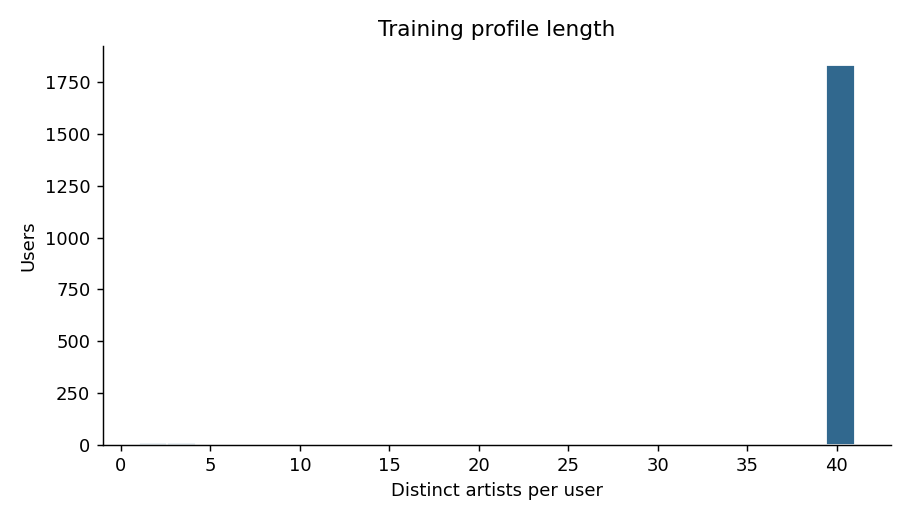

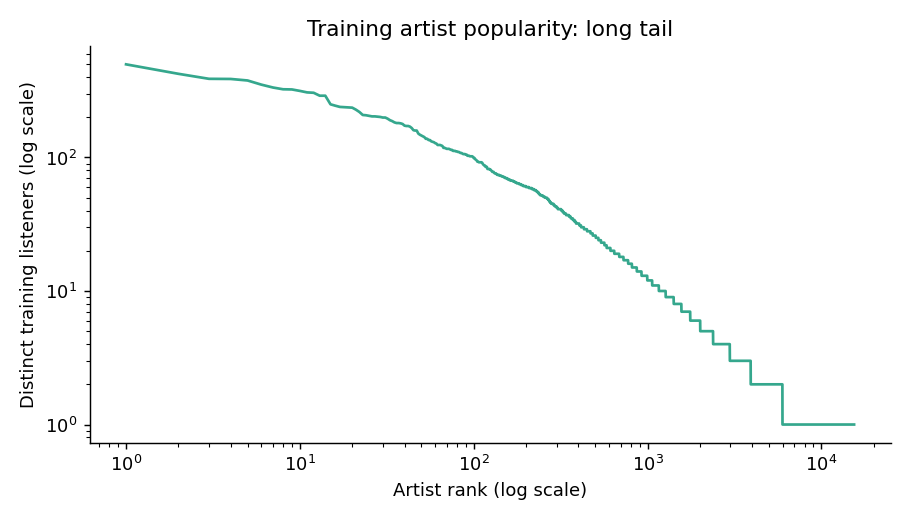

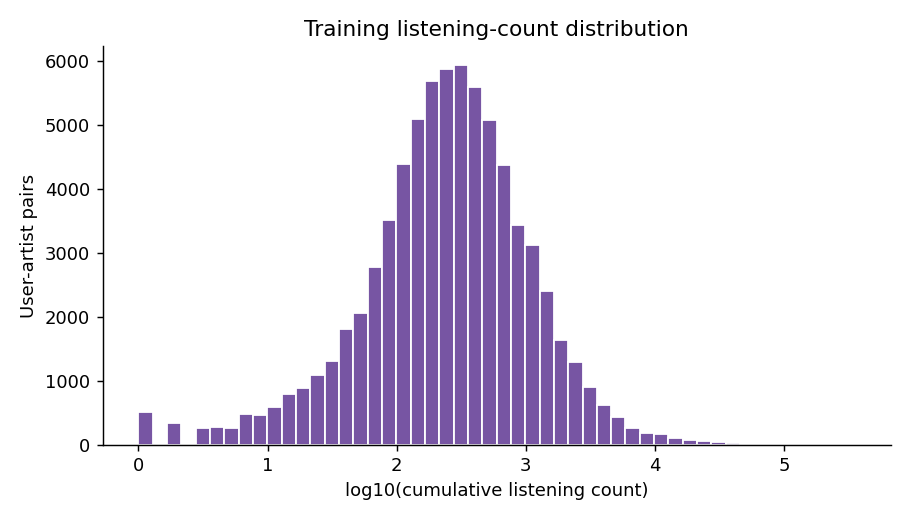

In [7]:
for name in ['01_user_activity.png','02_artist_long_tail.png','03_listening_counts.png']:
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / name)))


## 4. 统一指标和验证选择

对每位验证用户，从完整艺人目录去掉其训练历史；不抽样负例，也不利用测试答案过滤候选。正反馈缺失项是未知，离线评价不是线上满意度证明。冷艺人保留在分母中。

Precision@K=命中数/K；Recall@K=命中数/用户验证正例数；NDCG 按 log2(rank+1) 折扣并用理想排名归一化。先算每人，再等权平均。完整公式与最终测试方案见 docs/experiment_protocol.md。

In [8]:
columns = ['model','ndcg@10','recall@10','precision@10','hit_rate@10','catalogue_coverage@10','ndcg@20']
display(experiment['results'][columns].round(6))
print('验证选择的 ItemCF 基线:', experiment['selection'])
print('未选择最终模型；测试指标未计算。')


,model,ndcg@10,recall@10,precision@10,hit_rate@10,catalogue_coverage@10,ndcg@20
0,popularity,0.057249,0.065424,0.032658,0.246670,0.001531,0.072042
1,itemcf_n20_s0,0.128107,0.133964,0.066755,0.450186,0.189995,0.152441
2,itemcf_n50_s0,0.133977,0.138865,0.069206,0.468833,0.193739,0.158461
3,itemcf_n100_s0,0.141635,0.149014,0.074267,0.493340,0.195837,0.169325
4,itemcf_n20_s10,0.138174,0.145471,0.072509,0.492275,0.044068,0.167115
5,itemcf_n50_s10,0.142889,0.150693,0.075120,0.509323,0.047641,0.170446
6,itemcf_n100_s10,0.144629,0.151971,0.075759,0.510389,0.047868,0.174410


验证选择的 ItemCF 基线: itemcf_n100_s10
未选择最终模型；测试指标未计算。


## 5. 分组与不确定性

含冷目标用户并不意味着所有目标都冷，下表是用户组整体指标，不是“冷艺人召回率”。分组差异是相关观察，不是因果结论。

bootstrap 在同一验证拆分的用户上重采样，无法覆盖调参赢家偏差、不同拆分或模型种子波动。

In [9]:
display(pd.read_csv(ROOT / 'outputs' / 'validation_user_groups.csv').round(6))
display(pd.DataFrame({k:v for k,v in experiment['uncertainty'].items() if isinstance(v,dict)}).T)
print(experiment['uncertainty']['caution'])


,model,group,users,ndcg@10,recall@10
0,popularity,all,1877,0.057249,0.065424
1,popularity,has_cold_target,735,0.026740,0.031156
2,popularity,all_targets_warm,1142,0.076885,0.087478
3,popularity,train_degree_below_30,30,0.000000,0.000000
4,itemcf_n100_s10,all,1877,0.144629,0.151971
5,itemcf_n100_s10,has_cold_target,735,0.083296,0.087914
6,itemcf_n100_s10,all_targets_warm,1142,0.184103,0.193199
7,itemcf_n100_s10,train_degree_below_30,30,0.000000,0.000000


,mean,lower_95,upper_95,samples,seed
popularity_ndcg10,0.057249,0.051545,0.062875,1000.0,2026.0
selected_itemcf_ndcg10,0.144629,0.136683,0.153298,1000.0,2026.0
paired_itemcf_minus_popularity_ndcg10,0.087380,0.081443,0.093551,1000.0,2026.0


Validation split only; tuned-winner selection and random-split variability are not covered. No final superiority claim.


## 6. 独立协议测试

小样本手算验证余弦、收缩、稀疏方向、固定拆分、指标、冷目标与已见过滤。单元测试不等于完整模型正确性证明，但能发现常见实现错误。

In [10]:
tests = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                       cwd=ROOT, capture_output=True, text=True)
print(tests.stdout + tests.stderr)
tests.check_returncode()
print('Windows 实际运行:', experiment['runtime']['windows_execution_verified'])


content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 04: loss=0.35957, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 08: loss=0.15370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 12: loss=0.01681, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 16: loss=0.00026, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 04: loss=0.29278, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 0

## 7. 当前能说什么，下一步做什么

目前只有两个基线及 ItemCF 内部调参。验证结果支持在该随机留出与候选协议下继续以个性化 CF 为参照，不代表测试或线上提升。收缩配置的覆盖率变化值得一起报告，不能只选好看的准确率。

接下来以真实实验实现 BPR-MF、NeuMF、内容双塔并比较。标签特征必须仅由允许的训练信息构造，目录外标签先隔离。最终模型和超参冻结后才执行统一测试。没有真实结果的单元格不得用“预计提升”补齐。

**成员学习与记录：**解释指标、分析低活跃用户、核查标签编码与覆盖、填写真实分工和 AI 使用；Windows 验收结果单独记录。参见 docs/model_plan.md 与 docs/learning_and_contributions.md。

来源：[GroupLens HetRec](https://grouplens.org/datasets/hetrec-2011/)，原始 README 与 docs/research.md。